# King County házárak – regressziós modell

**5. házi feladat – Data Science kurzus**

A cél annak vizsgálata, hogy a King County házeladási adataiból mennyire pontosan becsülhető meg egy ingatlan eladási ára. A notebook a teljes munkafolyamatot bemutatja: EDA, indokolt tisztítás, leakage-mentes felosztás, baseline-ok és modellek, diagnosztika, feature-engineering visszacsatolás, majd egyszeri záró teszt.

## 1. Kérdés és célváltozó

A célváltozó az ingatlan eredeti eladási ára (`price`, USD). A nyers ár jobbra ferde, ezért a tisztességes lineáris modell `log_price = ln(price)` célváltozóra tanul, majd a jóslatot visszaalakítjuk USD-ra. A fő mutató az **RMSE**, mert a nagy összegű hibákat erősen bünteti; mellette MAE-t, WAPE-et, RMSLE-t és R²-et is közlünk. A túl- és alulbecslést a reziduumok irányával és kalibrációval is vizsgáljuk.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_squared_log_error
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE=42
DATA_DIR=Path("data")
CLEAN_PATH=DATA_DIR/"kc_house_data_cleaned.xlsx"
BEFORE_PATH=DATA_DIR/"kc_house_data_before_cleaning.xlsx"

## 2. Adatbetöltés és változószótár

A tisztított Excel első munkalapját használjuk. A második munkalap változólistája megjelenik a notebookban, így az olvasó pontosan látja a regressziós specifikációt.

In [2]:
clean_raw=pd.read_excel(CLEAN_PATH, sheet_name=0)
variable_guide=pd.read_excel(CLEAN_PATH, sheet_name=1)
raw_before=pd.read_excel(BEFORE_PATH, sheet_name=0)
rename_map={"sale_year (dummy)":"sale_year","price (USD)":"price","waterfront (dummy)":"waterfront","view (0-4)":"view","condition (0-5)":"condition","grade (1-13)":"grade","is_renovated (dummy)":"is_renovated"}
df=clean_raw.rename(columns=rename_map).copy()
df["sale_date"]=pd.to_datetime(df["sale_date"])
df["log_price"]=np.log(df["price"])
print(f"{df.shape[0]:,} sor, {df.shape[1]} oszlop")
display(variable_guide)

21,597 sor, 25 oszlop


,Változó neve,Szerepe a modellben,Típusa / Értelmezése
0,log_price,Függő változó (Y),Célváltozó (természetes logaritmus)
1,house_age,Független változó (X1​),A ház kora eladáskor (avulás)
2,bedrooms,Független változó (X2​),Hálószobák száma
3,bathrooms,Független változó (X3​),Fürdőszobák száma (tizedesekkel)
4,sqft_living,Független változó (X4​),Lakóterület nagysága (sqft)
5,sqft_lot,Független változó (X5​),Telek mérete (sqft)
6,floors,Független változó (X6​),Szintek száma
7,waterfront (dummy),Független változó (X7​),Tenger/tóparti ingatlan-e (0/1)
8,view (0-4),Független változó (X8​),Kilátás minősége (0−4 skála)
9,condition (0-5),Független változó (X9​),Szerkezeti állapot (1−5 skála)


### A regresszió fő változói

A második sheet alapján a cél `log_price`, a fő magyarázóváltozók: `house_age`, `bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`, `waterfront`, `view`, `condition`, `grade`, `is_renovated`, `sale_year`, `lat`, `long`. A tisztességes lineáris modellhez a `zipcode`-ot kategóriaként one-hot kódoljuk. Az `id`, a nyers dátum, a `price` mint bemenet és a nyers `yr_renovated` nem prediktor. A `sqft_living`, `sqft_above`, `sqft_basement` hármasból az alapmodell csak `sqft_living`-et használja, mert a másik kettő összege pontosan ezt adja.

## 3. EDA – első áttekintés

In [3]:
display(df.head())
display(df.describe(include="all").T)
eda_summary=pd.DataFrame({"dtype":df.dtypes.astype(str),"missing":df.isna().sum(),"unique":df.nunique()})
display(eda_summary)

,id,sale_date,sale_year,house_age,price,log_price,bedrooms,bathrooms,sqft_living,sqft_lot,...,sqft_above,sqft_basement,yr_built,yr_renovated,is_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,2014,59,221900,12.309982,3,1.00,1180,5650,...,1180,0,1955,0,0,98178,47.5112,-122.257,1340,5650
1,6414100192,2014-12-09,2014,63,538000,13.195614,3,2.25,2570,7242,...,2170,400,1951,1991,1,98125,47.7210,-122.319,1690,7639
2,5631500400,2015-02-25,2015,82,180000,12.100712,2,1.00,770,10000,...,770,0,1933,0,0,98028,47.7379,-122.233,2720,8062
3,2487200875,2014-12-09,2014,49,604000,13.311329,4,3.00,1960,5000,...,1050,910,1965,0,0,98136,47.5208,-122.393,1360,5000
4,1954400510,2015-02-18,2015,28,510000,13.142166,3,2.00,1680,8080,...,1680,0,1987,0,0,98074,47.6168,-122.045,1800,7503


,count,mean,min,25%,50%,75%,max,std
id,21597.0,4580474287.770987,1000102.0,2123049175.0,3904930410.0,7308900490.0,9900000190.0,2876735715.74778
sale_date,21597,2014-10-29 04:20:38.171968,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
sale_year,21597.0,2014.322962,2014.0,2014.0,2014.0,2015.0,2015.0,0.467619
house_age,21597.0,43.323841,0.0,18.0,40.0,63.0,115.0,29.376456
price,21597.0,540202.919757,78000.0,322000.0,450000.0,645000.0,7700000.0,367133.73089
log_price,21597.0,13.048142,11.264464,12.682307,13.017003,13.377006,15.856731,0.526418
bedrooms,21597.0,3.371811,1.0,3.0,3.0,4.0,11.0,0.904096
bathrooms,21597.0,2.115826,0.5,1.75,2.25,2.5,8.0,0.768984
sqft_living,21597.0,2080.32185,370.0,1430.0,1910.0,2550.0,13540.0,918.106125
sqft_lot,21597.0,15099.40876,520.0,5040.0,7618.0,10685.0,1651359.0,41412.636876


,dtype,missing,unique
id,int64,0,21420
sale_date,datetime64[us],0,372
sale_year,int64,0,2
house_age,int64,0,116
price,int64,0,4024
log_price,float64,0,4024
bedrooms,int64,0,11
bathrooms,float64,0,29
sqft_living,int64,0,1034
sqft_lot,int64,0,9776


### 3.1. Célváltozó-eloszlás

A `price` jobbra ferde: kevés luxusingatlan nagyon hosszú jobb oldali farkat okoz. A logaritmus szimmetrikusabbá teszi a skálát, és a lineáris modell számára stabilabb hibaszerkezetet adhat.

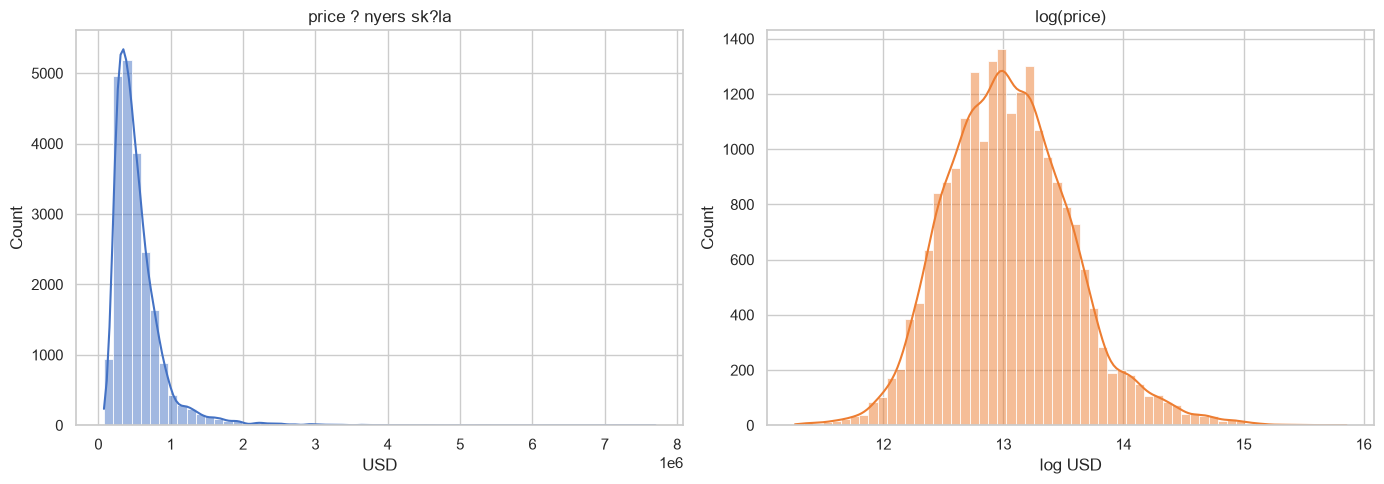

In [4]:
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.histplot(df.price,bins=60,kde=True,ax=ax[0],color="#4472C4"); ax[0].set_title("price – nyers skála"); ax[0].set_xlabel("USD")
sns.histplot(df.log_price,bins=60,kde=True,ax=ax[1],color="#ED7D31"); ax[1].set_title("log(price)"); ax[1].set_xlabel("log USD")
plt.tight_layout(); plt.show()

### 3.2. Lakóterület és ár

A `sqft_living` erős ármagyarázó változó, de az összefüggés szórása és görbüléte miatt nem tökéletes lineáris kapcsolat. Ez motiválja a faalapú modellek kipróbálását.

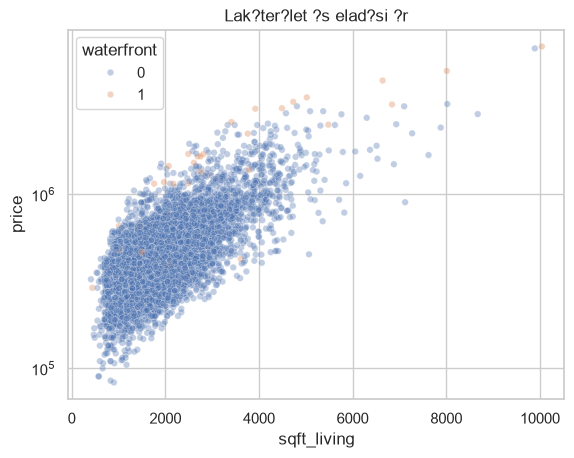

In [5]:
s=df.sample(min(6000,len(df)),random_state=RANDOM_STATE)
sns.scatterplot(data=s,x="sqft_living",y="price",hue="waterfront",alpha=.35,s=22)
plt.yscale("log"); plt.title("Lakóterület és eladási ár"); plt.show()

### 3.3. Korrelációs mátrix

A következő mátrix Pearson-korrelációkat mutat. Ez lineáris együttmozgás, nem ok-okozat; a `zipcode` kódot ezért nem szabad numerikus mennyiségként használni a lineáris modellben.

,price,log_price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15
price,1.000,0.892,0.316,0.526,0.702,0.090,0.257,0.605,0.324,0.054,0.126,0.307,0.022,0.585,0.083
log_price,0.892,1.000,0.351,0.551,0.695,0.100,0.311,0.602,0.317,0.081,0.114,0.449,0.051,0.619,0.092
bedrooms,0.316,0.351,1.000,0.528,0.593,0.034,0.184,0.493,0.309,0.161,0.019,-0.012,0.137,0.405,0.032
bathrooms,0.526,0.551,0.528,1.000,0.756,0.088,0.503,0.687,0.283,0.507,0.051,0.024,0.225,0.570,0.088
sqft_living,0.702,0.695,0.593,0.756,1.000,0.173,0.354,0.876,0.435,0.318,0.055,0.052,0.241,0.756,0.184
sqft_lot,0.090,0.100,0.034,0.088,0.173,1.000,-0.005,0.184,0.015,0.053,0.008,-0.086,0.230,0.145,0.718
floors,0.257,0.311,0.184,0.503,0.354,-0.005,1.000,0.524,-0.246,0.489,0.006,0.049,0.126,0.280,-0.011
sqft_above,0.605,0.602,0.493,0.687,0.876,0.184,0.524,1.000,-0.052,0.424,0.023,-0.001,0.345,0.732,0.195
sqft_basement,0.324,0.317,0.309,0.283,0.435,0.015,-0.246,-0.052,1.000,-0.133,0.071,0.110,-0.145,0.200,0.018
yr_built,0.054,0.081,0.161,0.507,0.318,0.053,0.489,0.424,-0.133,1.000,-0.225,-0.148,0.410,0.326,0.071


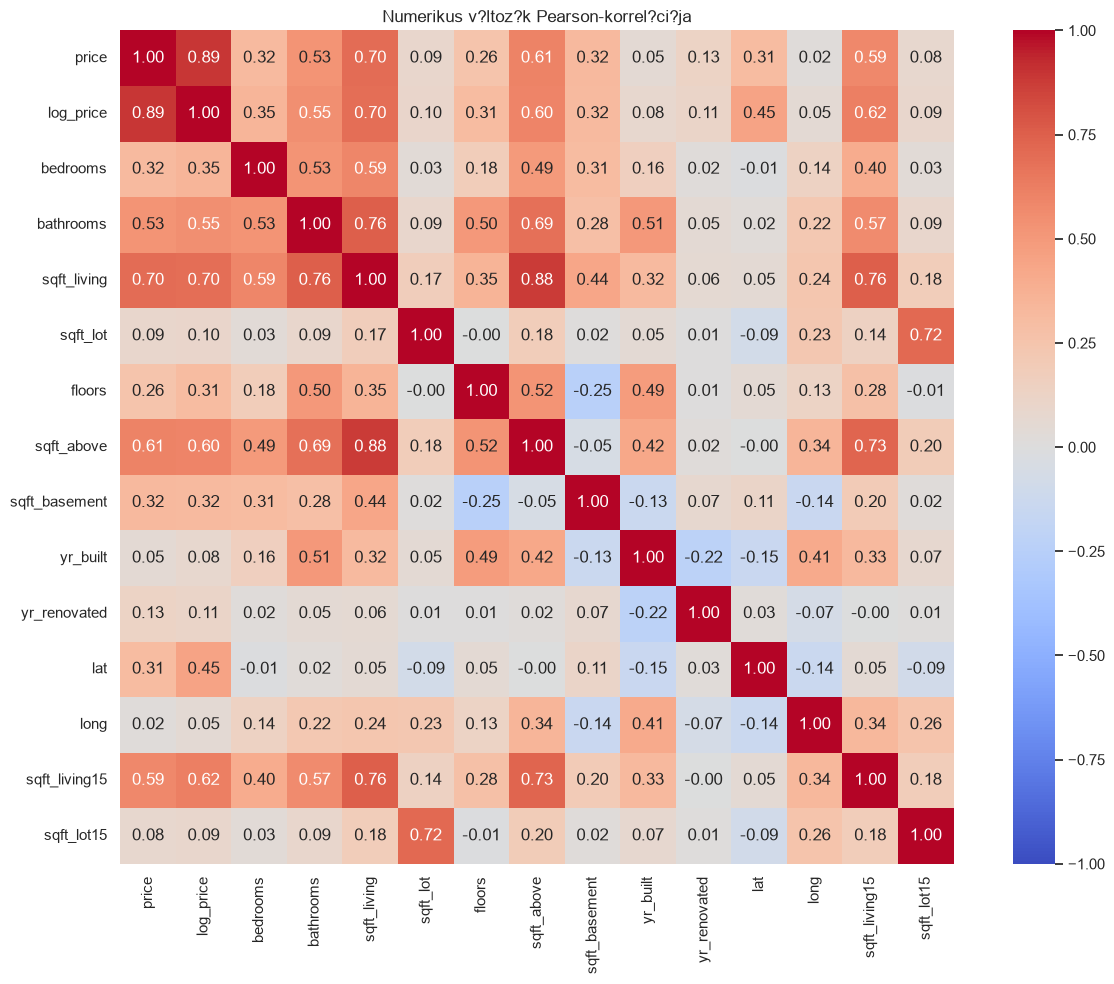

In [6]:
corr_cols=[c for c in ["price","log_price","bedrooms","bathrooms","sqft_living","sqft_lot","floors","sqft_above","sqft_basement","yr_built","yr_renovated","lat","long","sqft_living15","sqft_lot15"] if c in df]
corr=df[corr_cols].corr(); display(corr.round(3))
plt.figure(figsize=(13,10)); sns.heatmap(corr,cmap="coolwarm",center=0,vmin=-1,vmax=1,annot=True,fmt=".2f",square=True); plt.title("Numerikus változók Pearson-korrelációja"); plt.tight_layout(); plt.show()

### 3.4. Változószótár

In [7]:
display(variable_guide.style.set_properties(**{"text-align":"left"}))

,Változó neve,Szerepe a modellben,Típusa / Értelmezése
0,log_price,Függő változó (Y),Célváltozó (természetes logaritmus)
1,house_age,Független változó (X1​),A ház kora eladáskor (avulás)
2,bedrooms,Független változó (X2​),Hálószobák száma
3,bathrooms,Független változó (X3​),Fürdőszobák száma (tizedesekkel)
4,sqft_living,Független változó (X4​),Lakóterület nagysága (sqft)
5,sqft_lot,Független változó (X5​),Telek mérete (sqft)
6,floors,Független változó (X6​),Szintek száma
7,waterfront (dummy),Független változó (X7​),Tenger/tóparti ingatlan-e (0/1)
8,view (0-4),Független változó (X8​),Kilátás minősége (0−4 skála)
9,condition (0-5),Független változó (X9​),Szerkezeti állapot (1−5 skála)


## 4. Adattisztítás – lépésenként és indoklással

Az eredeti adat 21 613 sorból és 21 oszlopból állt; a tisztított változat 21 597 sort és 25 oszlopot tartalmaz. A döntések az adat belső ellentmondásaira és a házi követelményeire épülnek.

In [8]:
audit=pd.DataFrame({"állapot":["tisztítás előtt","tisztítás után"],"sorok":[len(raw_before),len(df)],"oszlopok":[raw_before.shape[1],df.shape[1]],"hiányzó cellák":[int(raw_before.isna().sum().sum()),int(df.isna().sum().sum())]}); display(audit)
print("Előtte: bedrooms=33",(raw_before.bedrooms==33).sum(),"; bedrooms=0",(raw_before.bedrooms==0).sum(),"; bathrooms=0",(raw_before.bathrooms==0).sum())
print("Utána: bedrooms=0",(df.bedrooms==0).sum(),"; bathrooms=0",(df.bathrooms==0).sum())

,?llapot,sorok,oszlopok,hi?nyz? cell?k
0,tiszt?t?s el?tt,21613,21,0
1,tiszt?t?s ut?n,21597,25,0


Előtte: bedrooms=33 1 ; bedrooms=0 13 ; bathrooms=0 10
Utána: bedrooms=0 0 ; bathrooms=0 0


### Tisztítási döntések

- A szöveges, szóközzel tagolt `price` numerikus lett; a numerikus értékeket ellenőriztük, nem módosítottuk.
- A szöveges `date` valódi `sale_date` dátummá alakult; ebből származik `sale_year`.
- A 33 hálószobás (`id=2402100895`) rekord 1620 sqft lakóterület mellett belsőleg ellentmondásos. A 33 nagy valószínűséggel 3-as adatbeviteli hiba, ezért 3-ra javítottuk.
- 13 rekordban 0 hálószoba, 10-ben 0 fürdőszoba szerepelt. Több ilyen sorban érdemi lakóterület volt, így az értékek nem illenek a lakóingatlan-adatbázis logikájához. A 16 érintett sort kevés előfordulásuk és nem megbízható imputálhatóságuk miatt eltávolítottuk.
- A 12 negatív `sale_year-yr_built` értéket 0 házkorra korlátoztuk; ez építés alatti/tervrajzról történő értékesítést jelenthet.
- `yr_renovated=0` esetén nincs felújítás, ezért létrejött az `is_renovated` indikátor; a nyers oszlopot az EDA kedvéért megtartottuk.
- `log_price=ln(price)` a lineáris modell célváltozója, az eredeti ár az értelmezéshez megmarad.
- `id` csak azonosító, nem prediktor. `zipcode` kategória, ezért a lineáris modellben one-hot kódoljuk.
- A `sqft_living = sqft_above + sqft_basement` azonosság miatt mindhárom változót nem használjuk egyszerre.

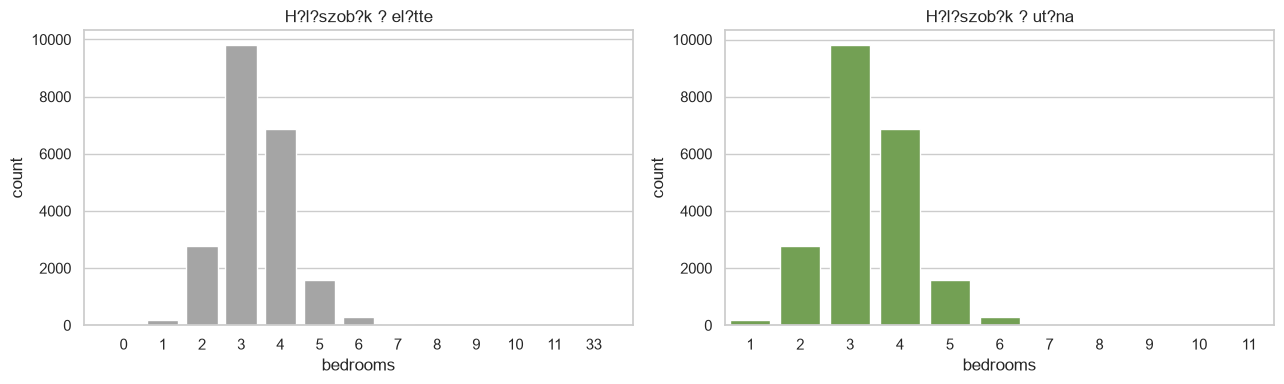

In [9]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.countplot(data=raw_before,x="bedrooms",ax=ax[0],color="#A5A5A5"); ax[0].set_title("Hálószobák – előtte"); ax[0].set_xlim(-1,13)
sns.countplot(data=df,x="bedrooms",ax=ax[1],color="#70AD47"); ax[1].set_title("Hálószobák – utána"); plt.tight_layout(); plt.show()

## 5. Ismétlődő ingatlanok és split

Az ismételt eladásokat a `lat`, `long`, `sqft_living`, `sqft_lot`, `yr_built`, `zipcode` összetett kulcsával csoportosítjuk. Időrendi tesztidőszakot zárolunk, majd a tesztben szereplő csoportokat kizárjuk a developmentből. A developmenten belül GroupKFold biztosítja, hogy egy ingatlan ne kerüljön két foldba.

In [10]:
property_cols=["lat","long","sqft_living","sqft_lot","yr_built","zipcode"]
df["property_group"]=df[property_cols].astype(str).agg("|".join,axis=1)
df=df.sort_values("sale_date").reset_index(drop=True)
cutoff=df.sale_date.quantile(.80); test_mask=df.sale_date>=cutoff; test_groups=set(df.loc[test_mask,"property_group"]); train_mask=(df.sale_date<cutoff)&(~df.property_group.isin(test_groups))
dev=df.loc[train_mask].reset_index(drop=True); test=df.loc[test_mask].reset_index(drop=True)
print("cutoff",cutoff.date(),"development",dev.shape,"test",test.shape,"közös csoport",len(set(dev.property_group)&set(test.property_group)))
print("dev",dev.sale_date.min().date(),"?",dev.sale_date.max().date(),"test",test.sale_date.min().date(),"?",test.sale_date.max().date())

cutoff 2015-03-10 development (17169, 26) test (4329, 26) közös csoport 0
dev 2014-05-02 ? 2015-03-09 test 2015-03-10 ? 2015-05-27


## 6. Mutatók és modellek

Minden modell ugyanazokat a GroupKFold foldokat kapja. A lineáris modell log-célon tanul, majd smearing-korrekcióval tér vissza USD-ra. A döntési fa, Random Forest és XGBoost nyers árat tanul. A lineáris modellben a `zipcode` one-hot kódolt.

In [11]:
base_features=["house_age","bedrooms","bathrooms","sqft_living","sqft_lot","floors","waterfront","view","condition","grade","is_renovated","sale_year","lat","long"]; cat_features=["zipcode"]
def metrics(y,p):
 y=np.asarray(y); p=np.asarray(p); q=np.clip(p,0,None); return {"RMSE":np.sqrt(mean_squared_error(y,p)),"MAE":mean_absolute_error(y,p),"WAPE":np.abs(y-p).sum()/np.abs(y).sum(),"RMSLE":np.sqrt(mean_squared_log_error(y,q)),"R2":r2_score(y,p),"negative_predictions":int((p<0).sum())}
def prep(features):
 num=[c for c in features if c not in cat_features]; return ColumnTransformer([("num",SimpleImputer(strategy="median"),num),("cat",OneHotEncoder(handle_unknown="ignore"),cat_features)])
def make_models(features=base_features):
 p=prep(features); return {"Tisztességes lineáris (Ridge, log-cél)":(Pipeline([("prep",p),("model",Ridge(alpha=1.0))]),"log"),"Döntési fa":(Pipeline([("prep",p),("model",DecisionTreeRegressor(max_depth=12,min_samples_leaf=10,random_state=RANDOM_STATE))]),"raw"),"Random Forest":(Pipeline([("prep",p),("model",RandomForestRegressor(n_estimators=250,min_samples_leaf=2,max_features=.8,n_jobs=-1,random_state=RANDOM_STATE))]),"raw"),"XGBoost":(Pipeline([("prep",p),("model",XGBRegressor(n_estimators=500,max_depth=6,learning_rate=.05,subsample=.85,colsample_bytree=.85,objective="reg:squarederror",n_jobs=-1,random_state=RANDOM_STATE))]),"raw")}
def fit_predict(est,t,Xtr,ytr,Xv):
 if t=="log": est.fit(Xtr,np.log(ytr)); smear=np.mean(ytr/np.exp(est.predict(Xtr))); return np.exp(est.predict(Xv))*smear
 est.fit(Xtr,ytr); return est.predict(Xv)
def grouped_cv(models,data,features):
 X=data[features+cat_features]; y=data.price; g=data.property_group; sp=GroupKFold(3); rows=[]; oof={}
 for name,(est,t) in models.items():
  pa=np.full(len(data),np.nan)
  for fold,(tr,va) in enumerate(sp.split(X,y,g),1):
   p=fit_predict(est,t,X.iloc[tr],y.iloc[tr],X.iloc[va]); pa[va]=p; r=metrics(y.iloc[va],p); r.update(model=name,fold=fold); rows.append(r)
  oof[name]=pa
 return pd.DataFrame(rows),pd.DataFrame(oof)

## 7. Baseline-ok és összehasonlítás

Az átlag baseline és a zipcode-medián baseline foldonként csak a tanítórészből számol. így a naiv szabály sem látja előre a validációs célértékeket.

RMSE                     MAE  \
                                              mean         std        mean   
model                                                                        
XGBoost                                 121231.389    4474.868   62577.689   
Random Forest                           128142.372    5420.138   67240.064   
D?nt?si fa                              179306.291   11452.939   89182.973   
Zipcode-medi?n baseline                 292739.723    8534.852  154972.115   
?tlag baseline                          367023.791    4636.530  233165.137   
Tisztess?ges line?ris (Ridge, log-c?l)  519561.842  250456.818  165271.412   

                                                   WAPE         RMSLE         \
                                             std   mean    std   mean    std   
model                                                                          
XGBoost                                  792.713  0.116  0.001  0.160  0.001   
Random Forest                           1821.337  0.125  0.003  0.171  0.002   
D?nt?si fa                              3050.960  0.166  0.005  0.214  0.004   
Zipcode-medi?n baseline                  756.170  0.288  0.001  0.365  0.003   
?tlag baseline                          1837.019  0.434  0.003  0.548  0.003   
Tisztess?ges line?ris (Ridge, log-c?l)  7818.604  0.307  0.014  0.373  0.006   

                                           R2        negative_predictions       
                                         mean    std                 mean  std  
model                                                                           
XGBoost                                 0.891  0.008                  0.0  0.0  
Random Forest                           0.878  0.008                  0.0  0.0  
D?nt?si fa                              0.761  0.025                  0.0  0.0  
Zipcode-medi?n baseline                 0.364  0.027                  0.0  0.0  
?tlag baseline                         -0.000  0.000                  0.0  0.0  
Tisztess?ges line?ris (Ridge, log-c?l) -1.299  1.890                  0.0  0.0

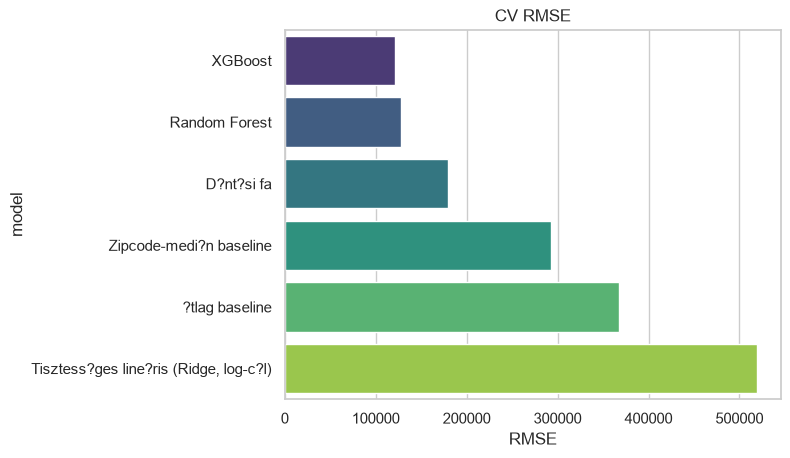

In [12]:
def baseline_cv(data):
 y=data.price; g=data.property_group; X=data[base_features+cat_features]; sp=GroupKFold(3); rows=[]; oo={}
 for name in ["átlag baseline","Zipcode-medián baseline"]:
  pa=np.full(len(data),np.nan)
  for fold,trva in enumerate(sp.split(X,y,g),1):
   tr,va=trva
   if name=="átlag baseline": p=np.repeat(y.iloc[tr].mean(),len(va))
   else: p=data.iloc[va].zipcode.map(data.iloc[tr].groupby("zipcode").price.median()).fillna(y.iloc[tr].median()).to_numpy()
   pa[va]=p; r=metrics(y.iloc[va],p); r.update(model=name,fold=fold); rows.append(r)
  oo[name]=pa
 return pd.DataFrame(rows),pd.DataFrame(oo)
models=make_models(); bs,bo=baseline_cv(dev); ms,mo=grouped_cv(models,dev,base_features); scores=pd.concat([bs,ms],ignore_index=True)
display(scores.groupby("model")[["RMSE","MAE","WAPE","RMSLE","R2","negative_predictions"]].agg(["mean","std"]).sort_values(("RMSE","mean")).round(3))
plot=scores.groupby("model",as_index=False).RMSE.mean().sort_values("RMSE"); sns.barplot(data=plot,x="RMSE",y="model",palette="viridis"); plt.title("CV RMSE"); plt.show()

### Értelmezés

Az elsődleges választás a development adaton mért, csoportos CV RMSE. A lineáris regresszió előnye a könnyű értelmezhetőség és az együtthatók kommunikálhatósága; a faalapú modellek előnye a nemlinearitás és az interakciók automatikus kezelése. A notebook nem előre feltételezi, hogy melyik algoritmus a legjobb: a záró modell a CV alapján kiválasztott jelölt lesz, miközben a lineáris regresszió teljes értékű, magyarázható benchmark marad.

## 8. Out-of-fold diagnosztika

CV legjobb: XGBoost


{'RMSE': np.float64(121286.43602697278),
 'MAE': 62577.68630416739,
 'WAPE': np.float64(0.11640162139964033),
 'RMSLE': np.float64(0.1597176982157551),
 'R2': 0.8908078107238782,
 'negative_predictions': 0}

,actual,predicted,n
decile,,,
1,217576.0,217741.0,1717
2,275151.0,274906.0,1717
3,323106.0,322863.0,1717
4,374287.0,374061.0,1717
5,429656.0,429237.0,1717
6,484732.0,486110.0,1716
7,548460.0,551645.0,1717
8,640864.0,638198.0,1717
9,772394.0,775880.0,1717


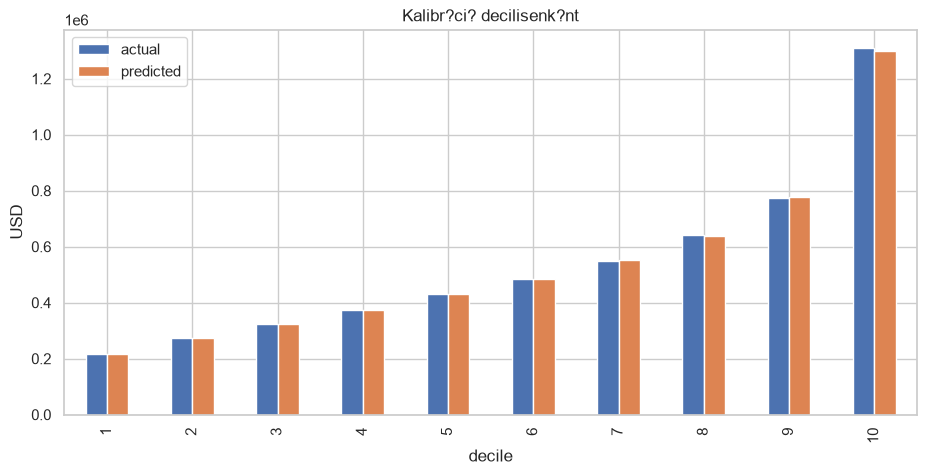

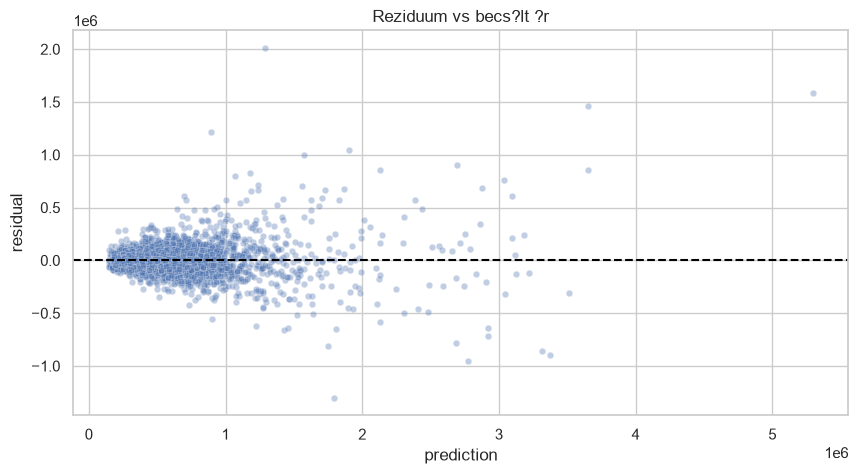

,mean,std,count
price_band,,,
"(77999.999, 295000.0]",-20926.0,46483.0,3454
"(295000.0, 397000.0]",-8763.0,53550.0,3423
"(397000.0, 515000.0]",-10448.0,65816.0,3435
"(515000.0, 700000.0]",2812.0,81990.0,3452
"(700000.0, 7700000.0]",40341.0,235942.0,3405


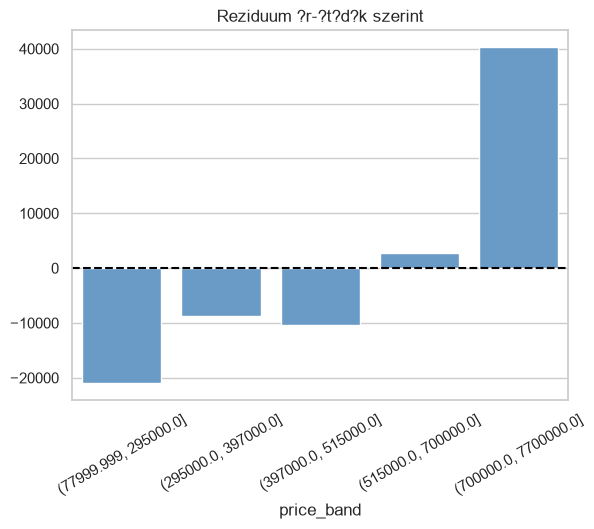

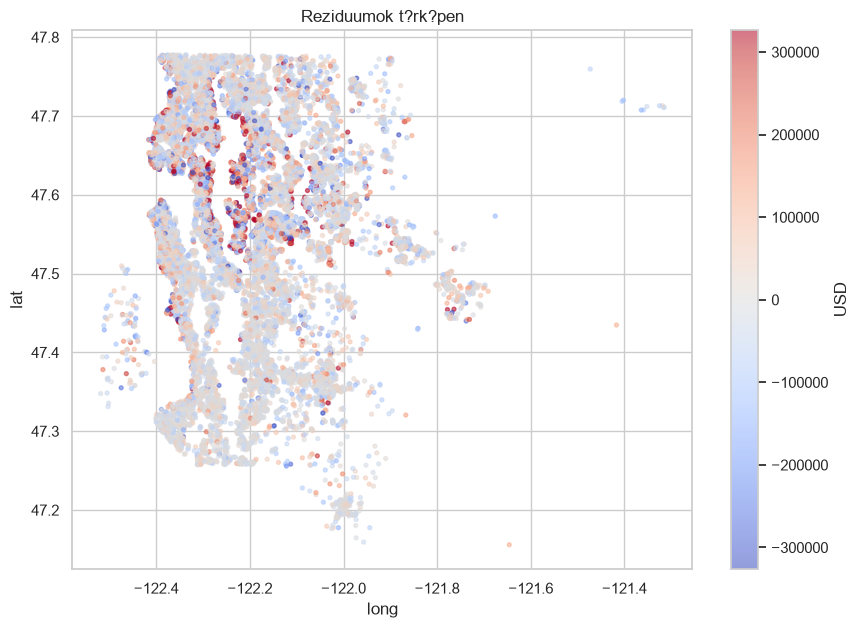

Negatív jóslatok: 0


In [13]:
best_name=ms.groupby("model").RMSE.mean().idxmin(); best_pred=mo[best_name].to_numpy(); oof=dev[["price","zipcode","lat","long","property_group"]].copy(); oof["prediction"]=best_pred; oof["residual"]=oof.price-oof.prediction; oof["price_band"]=pd.qcut(oof.price,5,duplicates="drop"); print("CV legjobb:",best_name); display(metrics(oof.price,oof.prediction))
oof["decile"]=pd.qcut(oof.prediction,10,labels=False,duplicates="drop")+1; cal=oof.groupby("decile").agg(actual=("price","mean"),predicted=("prediction","mean"),n=("price","size")); display(cal.round(0)); cal.plot(kind="bar",y=["actual","predicted"],figsize=(11,5),title="Kalibráció decilisenként"); plt.ylabel("USD"); plt.show()
plt.figure(figsize=(10,5)); sns.scatterplot(data=oof.sample(min(6000,len(oof)),random_state=RANDOM_STATE),x="prediction",y="residual",alpha=.35,s=22); plt.axhline(0,color="black",ls="--"); plt.title("Reziduum vs becsült ár"); plt.show()
by=oof.groupby("price_band",observed=True).residual.agg(["mean","std","count"]); display(by.round(0)); sns.barplot(x=by.index.astype(str),y=by["mean"].values,color="#5B9BD5"); plt.axhline(0,color="black",ls="--"); plt.xticks(rotation=30); plt.title("Reziduum ár-övek szerint"); plt.show()
plt.figure(figsize=(10,7)); lim=oof.residual.abs().quantile(.98); sc=plt.scatter(oof.long,oof.lat,c=oof.residual,cmap="coolwarm",vmin=-lim,vmax=lim,s=8,alpha=.55); plt.colorbar(sc,label="USD"); plt.title("Reziduumok térképen"); plt.xlabel("long"); plt.ylabel("lat"); plt.show()
print("Negatív jóslatok:",int((best_pred<0).sum()))

## 9. Visszacsatolási kör

**Hipotézis:** a faalapú modellek nehezebben tanulnak meg két oszlopból képzett arányokat és térbeli távolságokat. Ezért kipróbáljuk a `living_per_bedroom`, `living_per_lot` és Seattle/Bellevue közelebbi központjától mért `distance_to_city` feature-öket. Ezek nem használják a célváltozót, tehát nem okoznak target leakage-t. Ugyanazokat a foldokat alkalmazzuk.

In [14]:
def add_engineered(d):
 x=d.copy(); x["living_per_bedroom"]=x.sqft_living/x.bedrooms.clip(lower=1); x["living_per_lot"]=x.sqft_living/x.sqft_lot.clip(lower=1); se=(47.6062,-122.3321); be=(47.6101,-122.2015); x["distance_to_city"]=np.minimum(np.sqrt((x.lat-se[0])**2+(x.long-se[1])**2),np.sqrt((x.lat-be[0])**2+(x.long-be[1])**2)); return x
dev_e=add_engineered(dev); e_features=base_features+["living_per_bedroom","living_per_lot","distance_to_city"]; es,eo=grouped_cv(make_models(e_features),dev_e,e_features); fb=pd.concat([ms.groupby("model").RMSE.mean().rename("base_RMSE"),es.groupby("model").RMSE.mean().rename("engineered_RMSE")],axis=1); fb["improvement"]=fb.base_RMSE-fb.engineered_RMSE; display(fb.sort_values("engineered_RMSE").round(2))
a=ms.pivot(index="fold",columns="model",values="RMSE"); b=es.pivot(index="fold",columns="model",values="RMSE"); rows=[]
for n in a.columns:
 d=a[n]-b[n]; rows.append({"model":n,"fold_differences":d.round(1).tolist(),"mean_improvement":d.mean(),"std":d.std(ddof=1)})
display(pd.DataFrame(rows).sort_values("mean_improvement",ascending=False).round(2))

,base_RMSE,engineered_RMSE,improvement
model,,,
XGBoost,121231.39,119547.84,1683.55
Random Forest,128142.37,126566.50,1575.87
D?nt?si fa,179306.29,180656.90,-1350.61
"Tisztess?ges line?ris (Ridge, log-c?l)",519561.84,442794.84,76767.00


,model,fold_differences,mean_improvement,std
2,"Tisztess?ges line?ris (Ridge, log-c?l)","[175729.6, 52311.5, 2260.0]",76767.00,89283.14
3,XGBoost,"[6511.8, -4395.8, 2934.6]",1683.55,5560.35
1,Random Forest,"[-1059.0, 3599.4, 2187.2]",1575.87,2388.62
0,D?nt?si fa,"[-6253.3, 5580.5, -3379.0]",-1350.61,6172.16


## 10. Záró teszt – egyszer

A teszthalmazt nem használjuk modellválasztásra. A development/CV alapján kiválasztott specifikációt teljes development adaton újratanítjuk, majd egyszer értékeljük a zárolt teszten. A bootstrapot ingatlancsoportok szintjén végezzük.

In [15]:
base_best=ms.groupby("model").RMSE.mean().idxmin(); eng_best=es.groupby("model").RMSE.mean().idxmin();
if fb.loc[eng_best,"engineered_RMSE"]<fb.loc[base_best,"base_RMSE"]: final_name,final_features,final_dev,final_test,final_models=eng_best,e_features,dev_e,add_engineered(test),make_models(e_features)
else: final_name,final_features,final_dev,final_test,final_models=base_best,base_features,dev,test,models
est,t=final_models[final_name]; final_pred=fit_predict(est,t,final_dev[final_features+cat_features],final_dev.price,final_test[final_features+cat_features]);
mean_pred=np.repeat(dev.price.mean(),len(test)); zip_pred=test.zipcode.map(dev.groupby("zipcode").price.median()).fillna(dev.price.median()).to_numpy(); result=pd.DataFrame({"Választott modell":metrics(test.price,final_pred),"átlag baseline":metrics(test.price,mean_pred),"Zipcode-medián baseline":metrics(test.price,zip_pred)}).T; print("Végső modell:",final_name); display(result.round(3))

Végső modell: XGBoost


,RMSE,MAE,WAPE,RMSLE,R2,negative_predictions
V?lasztott modell,119850.941,69224.805,0.125,0.172,0.894,0.0
?tlag baseline,368018.298,232384.467,0.419,0.531,-0.002,0.0
Zipcode-medi?n baseline,298391.789,157896.495,0.285,0.366,0.341,0.0


In [16]:
def group_boot(y,p,g,n=300,seed=RANDOM_STATE):
 rng=np.random.default_rng(seed); z=pd.DataFrame({"y":y.to_numpy(),"p":np.asarray(p),"g":g.to_numpy()}); ug=z.g.unique(); out=[]
 for _ in range(n):
  ss=rng.choice(ug,size=len(ug),replace=True); boot=pd.concat([z[z.g==q] for q in ss]); out.append(np.sqrt(mean_squared_error(boot.y,boot.p)))
 return np.percentile(out,[2.5,50,97.5])
ci=group_boot(test.price,final_pred,test.property_group); print(f"Teszt-RMSE 95%-os csoportos bootstrap CI: [{ci[0]:,.0f}, {ci[2]:,.0f}] USD; medián {ci[1]:,.0f} USD")

Teszt-RMSE 95%-os csoportos bootstrap CI: [111,265, 127,312] USD; medián 119,771 USD


## 11. Korlátok

1. A minta egyetlen, kb. 13 hónapos időszak; más piaci ciklusban változhat a teljesítmény.
2. A többszörös eladások csoportkulcsa a rendelkezésre álló mezők közelítése, nem hivatalos ingatlanazonosító.
3. Az időrendi határ és a három GroupKFold felosztás ésszerű, de nem az egyetlen validációs terv.
4. A log-cél visszaalakítása smearing-korrekciót használ, de a heteroszkedaszticitást nem szünteti meg teljesen.
5. A koordinátatávolság közelítő euklideszi távolság, nem valós közúti távolság.
6. A záró teszt egyszeri becslés; ezért bootstrap-intervallumot is közlünk.

## 12. Összegzés

A notebook bemutatja az EDA-t, a tisztítás minden fontos döntését és indokát, a leakage-mentes időrendi és csoportos splitet, az átlagos és zipcode-medián baseline-t, a lineáris, döntési fás, Random Forest és XGBoost modelleket, valamint a diagnosztikából levezetett feature-engineering kört. A végső modell kiválasztása csak a development adaton történik; a tesztet egyszer használjuk.